#Alberto Model + Preprocessing: removal of [url] and @user mentions + emoji tokens

# Workflow

1. Load and inspect the data.
2. Select the political training and test subsets; inspect labels, duplicates, text lengths and special characters.
3. Clean and split the data. Remove URLs and mentions, separate emojis and normalize whitespace. Inspect conflicting labels before removing duplicate cleaned texts.
4. Train - Val split 90% training / 10% validation split using seed 42, and check overlap between splits.
5. Prepare and fine-tune AlBERTo.
- Load the tokenizer and binary classification model.
- Count emojis only in the training partition, add frequent unsupported emojis and resize the embeddings.
- Tokenize cleaned text with a maximum length of 256 and dynamic padding.
- Fine-tune at 5e-6, evaluating every 100 steps and selecting the best validation macro-F1 checkpoint.

6. Evaluate and errors analysis
- Evaluation on the test set: accuracy, macro-F1, HATE precision/recall/F1 and the confusion matrix.
- Export validation/test predictions, false positives and false negatives.

## Libraries import & Installs

In [ ]:
pip install emoji

In [ ]:
import pandas as pd
import re
import collections
import gc
import matplotlib.pyplot as plt


In [ ]:
import re
import regex
import emoji


In [ ]:
import html
import re
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import torch

from datasets import Dataset
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
)
from sklearn.model_selection import train_test_split
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
    set_seed,
)

from transformers import AddedToken
from transformers import EarlyStoppingCallback

In [ ]:
ERROR_DIR = Path(
    "/content/drive/MyDrive/master_unipa/baseline_error_analysis2"
)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Import data

In [ ]:
training_textual_path = '/content/drive/MyDrive/master_unipa/training_textual.csv'
training_contextual_path = '/content/drive/MyDrive/master_unipa/training_contextual.csv'

test_textual_path = '/content/drive/MyDrive/master_unipa/test_textual_gold.csv'
test_contextual = '/content/drive/MyDrive/master_unipa/test_contextual.csv'


In [ ]:
df_train = pd.read_csv(training_textual_path)
df_train_contextual = pd.read_csv(training_contextual_path)

df_test = pd.read_csv(test_textual_path)
df_test_contextual = pd.read_csv(test_contextual)

## 1. Exploratory Data Analysis

In [ ]:
df_train.head(2)
display(df_train.head(3))
display(df_train.shape)
display(df_train.label.value_counts())
display(df_train.dataset.value_counts())

print(f'Are tweets ids unique? {df_train["anonymized_tweet_id"].is_unique}')
print(f'Are there any repeated lines? {df_train.duplicated().any()}')


,anonymized_tweet_id,anonymized_text,label,dataset
0,217874450618134,@unknown Con tutte le denunce che si sta becca...,1,training_politics
1,360042217507605,#PRESCRIZIONE : I (t)re magi hanno trovato l’a...,0,training_politics
2,817917484817935,Il #m5s ha votato contro le #unionicivili addu...,1,training_politics


(5600, 4)

,count
label,
0,3456
1,2144


,count
dataset,
training_politics,5600


Are tweets ids unique? True
Are there any repeated lines? False


In [ ]:
print(df_test["dataset"].value_counts())

df_train = df_train.loc[
    df_train["dataset"].eq("training_politics")
].copy()

df_test = df_test.loc[
    df_test["dataset"].eq("test_politics")
].copy()

assert len(df_train) == 5600
assert len(df_test) == 1400

dataset
test_religious    3000
test_politics     1400
Name: count, dtype: int64


In [ ]:
df_test["dataset"].value_counts()

,count
dataset,
test_politics,1400


In [ ]:
df_test.head(2)

,anonymized_tweet_id,anonymized_text,label,dataset
0,424801448454884,questo anno #babbonatale portato giocattolo it...,1,test_politics
1,775194088981616,Adesso che in mezzo alla strada grazie al verg...,1,test_politics


In [ ]:
df_train["anonymized_tweet_id"].is_unique

True

In [ ]:
df_train['anonymized_tweet_id'].duplicated().any()

np.False_

In [ ]:
df_train_contextual.head(2)
display(df_train_contextual.head(3))
display(df_train_contextual.shape)
display(df_train_contextual.columns)
display(df_train.dataset.value_counts())
assert (df_train.anonymized_tweet_id == df_train_contextual.anonymized_tweet_id).all()

print(f'Are tweets ids unique? {df_train_contextual["anonymized_tweet_id"].is_unique}')
print(f'Are there any repeated lines? {df_train_contextual.duplicated().any()}')

,anonymized_tweet_id,created_at,retweet_count,favorite_count,source,is_reply,is_retweet,is_quote,anonymized_user_id,user_created_at,statuses_count,followers_count,friends_count,anonymized_description,dataset
0,217874450618134,2018-08-11,0.0,6.0,"<a href=""http://twitter.com/download/iphone"" r...",1.0,0.0,0.0,8.868893e+14,2018-04-01,554.0,748.0,753.0,Avete presente quegli stereotipi sui siciliani...,training_politics
1,360042217507605,2018-11-08,154.0,448.0,"<a href=""http://twitter.com/download/iphone"" r...",0.0,0.0,0.0,2.570741e+14,2011-10-26,35043.0,10838.0,4535.0,Prof di latino e Deputata PD.Ama lo sport la R...,training_politics
2,817917484817935,2018-11-10,195.0,638.0,"<a href=""http://twitter.com/download/iphone"" r...",0.0,0.0,0.0,6.908473e+14,2009-09-24,139750.0,7971.0,1866.0,"Medico, appassionato di Cinema d'Autore, Music...",training_politics


(5600, 15)

Index(['anonymized_tweet_id', 'created_at', 'retweet_count', 'favorite_count',
       'source', 'is_reply', 'is_retweet', 'is_quote', 'anonymized_user_id',
       'user_created_at', 'statuses_count', 'followers_count', 'friends_count',
       'anonymized_description', 'dataset'],
      dtype='object')

,count
dataset,
training_politics,5600


Are tweets ids unique? True
Are there any repeated lines? False


Special symbols analysis

In [ ]:
df_train

,anonymized_tweet_id,anonymized_text,label,dataset
0,217874450618134,@unknown Con tutte le denunce che si sta becca...,1,training_politics
1,360042217507605,#PRESCRIZIONE : I (t)re magi hanno trovato l’a...,0,training_politics
2,817917484817935,Il #m5s ha votato contro le #unionicivili addu...,1,training_politics
3,172580609652325,La #Lega e il #m5s stanno dando a bere all'opi...,0,training_politics
4,145836038456701,Che cosa cambia questa #legge? Caro @667517147...,0,training_politics
...,...,...,...,...
5595,715670659156960,#Covid. #Draghi non fare come #Conte. La #poli...,0,training_politics
5596,512309888296620,"Cina, «128mila euro a neonato»: la proposta pe...",0,training_politics
5597,887061502405620,@401560935985106 @507718538254873 @28429789767...,1,training_politics
5598,531900858879345,"Trasporto pubblico, Simeone nominato consiglie...",0,training_politics


In [ ]:

all_symbols = df_train['anonymized_text'].str.findall(r"[!\"#$%&()*+,-./:;<=>?[\\\]^_`{|}~]")
alphas = df_train['anonymized_text'].str.findall(r"[@]")
all_characters = df_train['anonymized_text'].str.findall(r".", flags=re.DOTALL)

# Count the characters found
total = all_characters.str.len().sum()

# Count the numbers of symbols
total_signes = all_symbols.str.len().sum()
total_alphas = alphas.str.len().sum()

print(f"Total characters: {total}")


print(f"Total punctuaction signs: {total_signes}")
print(f"% punctuaction signs: {(total_signes/total) *100}")

print(f"Total alphas: {total_alphas}")
print(f"% alphas signs: {(total_alphas/total) *100}")


Total characters: 1069177
Total punctuaction signs: 47711
% punctuaction signs: 4.462404260473242
Total alphas: 3613
% alphas signs: 0.3379234682377193


### URL count

In [ ]:
url_count = df_train['anonymized_text'].str.count(r"\[URL\]")

url_count.sum()

np.int64(1585)

### Basic statics

count    5600.000000
mean      190.924464
std        75.138851
min        24.000000
25%       127.000000
50%       196.000000
75%       263.000000
max       740.000000
Name: anonymized_text, dtype: float64


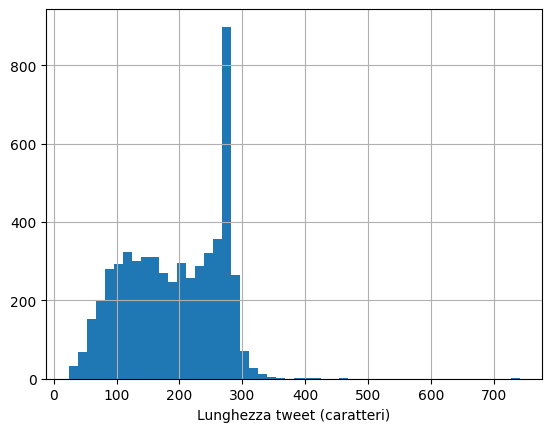

In [ ]:
# Statistiche descrittive senza modificare il testo.
print(df_train['anonymized_text'].str.len().describe())
df_train['anonymized_text'].str.len().hist(bins=50)
plt.xlabel('Lunghezza tweet (caratteri)')
plt.show()

### Load and validate data

In [ ]:
# 3. Load and validate each split
def load_split(path):
    df = pd.read_csv(path)

    text_column = (
        "text_clean" if "text_clean" in df.columns
        else "anonymized_text"
    )

    required = {text_column, "label"}
    if not required.issubset(df.columns):
        raise ValueError(
            f"{path}: expected text_clean or anonymized_text, plus label."
        )

    if df[[text_column, "label"]].isna().any().any():
        raise ValueError(f"{path}: missing text or labels; inspect these rows.")

    labels = pd.to_numeric(df["label"], errors="raise")
    if not labels.isin([0, 1]).all():
        raise ValueError(f"{path}: labels must be 0 or 1.")

    # Already-cleaned input is used unchanged.
    if text_column == "text_clean":
        text = df[text_column].astype(str).str.strip()
    else:
        text = df[text_column].map(clean_text)

    if text.eq("").any():
        raise ValueError(f"{path}: empty text after preprocessing.")

    result = pd.DataFrame({
        "text": text,
        "labels": labels.astype(int),
    })

    print(f"\n{path}: {len(result)} rows")
    print(result["labels"].value_counts().sort_index())

    return result.reset_index(drop=True)

## Pre-processing

- we focus on the tweet's text
- we remove '[URL]' and mentions of users
- we remove whitespaces

In [ ]:
import re

def clean_text(text):
    pattern = (
        r"https?://\S+"   # URL starting by http:// ou https://
        r"|www\.\S+"      # URL starting by www.
        r"|\[url\]"       # [url] ou [URL], [] included in the pattern
        r"|(?<!\w)@\w+"   # user mention/tag (@unknown, @500068400229841, @user_123)
                         # (?<!\w) : avoids @ preceded by a letter or digit like in a e-mail adress

    )

    # found elements replaced by a space
    text = re.sub(pattern, " ", text, flags=re.IGNORECASE)

    # eliminates empty [] or with whitespaces and break lines
    text = re.sub(r"\[\s*\]", " ", text)



    text = text.translate(str.maketrans({   # normalization
            "“": '"',
            "”": '"',
            "‘": "'",
            "’": "'",
        }))


    text = emoji.replace_emoji(         # add spaces before and after emojis
            text,
            replace=lambda chars, data: f" {chars} ",)


    replacements = {
            "❤️": " cuore ",
            "❤": " cuore ",
            ":)": " sorriso ",
            ":(": " tristezza ",
        }

    for symbol, replacement in replacements.items():
            text = text.replace(symbol, replacement)

    # \s+ : matches and replaces multiple spaces,
    # strip() : eliminates spaces at the beginning or at the end
    return re.sub(r"\s+", " ", text).strip()

In [ ]:
text_example = 'Hello👋World"'


text_test = emoji.replace_emoji(
    text_example,
    replace=lambda chars, data: f" {chars} ",
)

text_test = " ".join(text_test.split())

print(text_test)

Hello 👋 World"


### Check and Pre-process

In [ ]:
for df in (df_train, df_test):
    if df["anonymized_text"].isna().any():
        raise ValueError("Missing tweet text: inspect these rows first.")

    df["text_clean"] = df["anonymized_text"].map(clean_text)

display(df_train.head(2))
display(df_test.head(2))
df_test.to_csv('test.csv')

,anonymized_tweet_id,anonymized_text,label,dataset,text_clean
0,217874450618134,@unknown Con tutte le denunce che si sta becca...,1,training_politics,"Con tutte le denunce che si sta beccando, Salv..."
1,360042217507605,#PRESCRIZIONE : I (t)re magi hanno trovato l’a...,0,training_politics,#PRESCRIZIONE : I (t)re magi hanno trovato l'a...


,anonymized_tweet_id,anonymized_text,label,dataset,text_clean
0,424801448454884,questo anno #babbonatale portato giocattolo it...,1,test_politics,questo anno #babbonatale portato giocattolo it...
1,775194088981616,Adesso che in mezzo alla strada grazie al verg...,1,test_politics,Adesso che in mezzo alla strada grazie al verg...


### Tweets length after pre processing

count    5600.000000
mean      178.154107
std        74.194470
min        11.000000
25%       115.000000
50%       183.000000
75%       249.000000
max       284.000000
Name: text_clean, dtype: float64


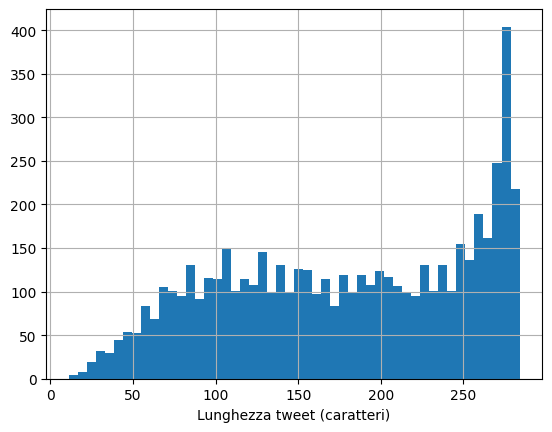

In [ ]:
# Statistiche descrittive senza modificare il testo.
print(df_train['text_clean'].str.len().describe())
df_train['text_clean'].str.len().hist(bins=50)
plt.xlabel('Lunghezza tweet (caratteri)')
plt.show()

In [ ]:
# Unique labels check
label_counts = df.groupby("text_clean")["label"].nunique()

conflicts = label_counts[label_counts > 1]

print(f"❌ Found {len(conflicts)} text(s) with contradictory labels :\n")
for text in conflicts.index:
    print(f"Text : {repr(text)}")

    associated_labels = df[df["text_clean"] == text]["label"].unique()
    print(f"Associated labels : {associated_labels}\n")


❌ Found 0 text(s) with contradictory labels :




### Check duplicates on the clean/preproccesed text before splittin

#### Drop duplicates in the train dataset

In [ ]:
df = df_train.copy()

if df.groupby("text_clean")["label"].nunique().gt(1).any():
    #raise ValueError("Some identical texts have conflicting labels.")

    df = df.drop_duplicates(subset="text_clean").reset_index(drop=True)

## Train/validation split

- we obtain the validation set by spliting the training data
- 10% will become validation
- seed set (42) for reproducibility

In [ ]:
if df.groupby("text_clean")["label"].nunique().gt(1).any():
    raise ValueError("Some identical texts have conflicting labels.")

train_df, val_df = train_test_split(
    df,
    test_size=0.10,
    random_state=42,
    stratify=df["label"],  # Preserve approximate class proportions
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

train_df.to_csv("train.csv", index=False)
val_df.to_csv("validation.csv", index=False)

print(f"Train: {len(train_df)} | Validation: {len(val_df)}")
print("Train proportions:\n", train_df["label"].value_counts(normalize=True))
print("Validation proportions:\n", val_df["label"].value_counts(normalize=True))

Train: 5026 | Validation: 559
Train proportions:
 label
0    0.61739
1    0.38261
Name: proportion, dtype: float64
Validation proportions:
 label
0    0.617174
1    0.382826
Name: proportion, dtype: float64


In [ ]:
train_df = load_split("train.csv")
val_df = load_split("validation.csv")
test_df = load_split('test.csv')



train.csv: 5026 rows
labels
0    3103
1    1923
Name: count, dtype: int64

validation.csv: 559 rows
labels
0    345
1    214
Name: count, dtype: int64

test.csv: 1400 rows
labels
0    700
1    700
Name: count, dtype: int64


## Model and Tokenizer

In [ ]:
# 1. Configuration
MODEL_NAME = (
    "m-polignano-uniba/"
    "bert_uncased_L-12_H-768_A-12_italian_alb3rt0"
)

SEED = 42
MAX_LENGTH = 256  # Tokens, not characters
OUTPUT_DIR = Path("alberto_run") # output directory

set_seed(SEED)

In [ ]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    classifier_dropout=0.2,
    #hidden_dropout_prob=0.2,
    id2label={0: "NON_HATE", 1: "HATE"},
    label2id={"NON_HATE": 0, "HATE": 1})

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  740MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: m-polignano-uniba/bert_uncased_L-12_H-768_A-12_italian_alb3rt0
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialize

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize(batch):
    return tokenizer(
        batch["text"], # Padding dinamico per ogni batch.
        truncation=True,
        max_length=MAX_LENGTH,

    )

vocab.txt:   0%|          | 0.00/1.11M [00:00<?, ?B/s]

## Add emojis to the tokenizer

1. check if the emojis in the train set appearing more than 2 times are present in the tokenizer
2. Adds them to the tokenizer vocab if they are absent


In [ ]:
# threshold
MIN_EMOJI_COUNT = 2

# Count only the training partition, after train/validation splitting.
emoji_counts = Counter(
    match["emoji"]
    for text in train_df["text"].fillna("")
    for match in emoji.emoji_list(text)
)

def unsupported(symbol):
    ids = tokenizer.encode(symbol, add_special_tokens=False)
    return not ids or tokenizer.unk_token_id in ids

emoji_tokens = sorted(
    symbol
    for symbol, count in emoji_counts.items()
    if count >= MIN_EMOJI_COUNT and unsupported(symbol)
)

num_added = tokenizer.add_tokens([
    AddedToken(
        symbol,
        normalized=False,
        single_word=False,
        lstrip=False,
        rstrip=False,
    )
    for symbol in emoji_tokens
])

if num_added:
    model.resize_token_embeddings(len(tokenizer))

print("Emoji tokens added:", num_added)
print("Selected emojis:", emoji_tokens)

for symbol in emoji_tokens:
    assert tokenizer.tokenize(symbol) == [symbol]

assert model.get_input_embeddings().num_embeddings == len(tokenizer)

[transformers] The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `mean_resizing=False`


Emoji tokens added: 102
Selected emojis: ['‼️', '⁉️', '▶️', '☠️', '⚠️', '⚡', '✅', '✊', '✌️', '✔', '✔️', '❌', '❓', '❗', '➡', '➡️', '⤵️', '⬇️', '🇨🇳', '🇪🇺', '🇮🇹', '🇱🇷', '🌹', '🌾', '🍒', '🍺', '🍾', '🎪', '🎶', '🏴\u200d☠️', '🐬', '🐲', '👆', '👇', '👇🏼', '👉', '👋', '👌', '👎', '👎🏻', '👏🏻', '💔', '💤', '💥', '💩', '💪', '💸', '📣', '📲', '🔥', '🔴', '🔵', '🔸', '🔽', '🖐', '🖕', '🖕🏻', '🖤', '🗽', '😀', '😅', '😆', '😎', '😑', '😒', '😡', '😤', '😬', '😲', '😳', '😶', '😷', '🙂', '🙄', '🙉', '🙊', '🛑', '🤐', '🤑', '🤔', '🤗', '🤚', '🤞', '🤞🏻', '🤡', '🤢', '🤣', '🤦\u200d♀️', '🤦\u200d♂️', '🤦🏻\u200d♀️', '🤦🏻\u200d♂️', '🤧', '🤫', '🤬', '🤭', '🤮', '🤷\u200d♂️', '🤷🏻\u200d♂️', '🥎', '🦄', '🧐', '🪴']


### make dataset

In [ ]:
def make_dataset(frame):
    dataset = Dataset.from_pandas(frame, preserve_index=False)
    return dataset.map(
        tokenize,
        batched=True,
        remove_columns=["text"],
    )


train_dataset = make_dataset(train_df)
val_dataset = make_dataset(val_df)
test_dataset = make_dataset(test_df)

collator = DataCollatorWithPadding(tokenizer=tokenizer)

Map:   0%|          | 0/5026 [00:00<?, ? examples/s]

Map:   0%|          | 0/559 [00:00<?, ? examples/s]

Map:   0%|          | 0/1400 [00:00<?, ? examples/s]

Tokenizer check

In [ ]:
examples = [

    # Hashtags
    "#Vergogna 🤡!!!",
    "#labuonascuola",
    "#25aprile",
    "#COVID19",

    # Mentions
    "Ciao @mario!",
    "Rispondo a @943206476637778.",

    # URLs and existing placeholders
    "[url]",
    "[URL]",
    "Guarda https://example.com!",

    "#salvinimerda✊",
    "#SperanzaDimettiti [URL]"
    "#COVIDー19",
    "#salviniemelonibuffoni",
    "#m5sscialtroni",
    "#m5scialtroni",
    "#m5spd",
    "#contenuto",
    "#renzioti",

    # Letter–number boundaries
    "49milioni",
    "aprile25",
    "25aprile2026",
    "prima25dopo",
    "Covid19",
    "Covid_19",
    "Covid-19",

    # Quotes and apostrophes
    "“Non sono d’accordo”",
    "‘Una citazione’",

    # Emojis and punctuation
    "❤ ❤️ 🤡 😂",
    "teatro🤡",
    "Ma certo...!!! :)",
    "pd.ama",
    "#VedovaDiConte #Marcotravaglio",
    "Il #gustodelfuturo....io sento odore di merda!!!!...#Draghi #RecoveryPlan"
]

for text in examples:
    processed = clean_text(text)
    tokenized = tokenizer.tokenize(processed)
    print(repr(text), "->", repr(tokenized))


'#Vergogna 🤡!!!' -> ['[UNK]', 'vergogna', '🤡', '!', '!', '!']
'#labuonascuola' -> ['[UNK]', 'lab', '##uo', '##nas', '##cuola']
'#25aprile' -> ['[UNK]', '[UNK]']
'#COVID19' -> ['[UNK]', '[UNK]']
'Ciao @mario!' -> ['ciao', '!']
'Rispondo a @943206476637778.' -> ['rispondo', 'a', '[UNK]']
'[url]' -> []
'[URL]' -> []
'Guarda https://example.com!' -> ['guarda']
'#salvinimerda✊' -> ['[UNK]', 'salvini', '##merda', '✊']
'#SperanzaDimettiti [URL]#COVIDー19' -> ['[UNK]', 'speranza', '##dimettiti', '[UNK]', '[UNK]']
'#salviniemelonibuffoni' -> ['[UNK]', 'salvini', '##eme', '##loni', '##buffon', '##i']
'#m5sscialtroni' -> ['[UNK]', '[UNK]']
'#m5scialtroni' -> ['[UNK]', '[UNK]']
'#m5spd' -> ['[UNK]', '[UNK]']
'#contenuto' -> ['[UNK]', 'contenuto']
'#renzioti' -> ['[UNK]', 'renzi', '##oti']
'49milioni' -> ['[UNK]']
'aprile25' -> ['[UNK]']
'25aprile2026' -> ['[UNK]']
'prima25dopo' -> ['[UNK]']
'Covid19' -> ['[UNK]']
'Covid_19' -> ['cov', '##id', '[UNK]', '[UNK]']
'Covid-19' -> ['cov', '##id', '[UNK]',

## Trainer and evaluation metrics

- best checkpoint is selected using validation macro-F1


In [ ]:
# Evaluation metrics Accuracy, Precision, Recall and F1 score
def compute_metrics(eval_prediction):
    logits, labels = eval_prediction
    if isinstance(logits, tuple):
        logits = logits[0]

    predictions = np.argmax(logits, axis=-1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="binary",
        pos_label=1,
        zero_division=0,
    )

    return {
        "accuracy": accuracy_score(labels, predictions),
        "macro_f1": f1_score(
            labels,
            predictions,
            labels=[0, 1],
            average="macro",
            zero_division=0,
        ),
        "hate_precision": precision,
        "hate_recall": recall,
        "hate_f1": f1,
    }


# Fine-tuning configuration
training_args = TrainingArguments(
    learning_rate=5e-6,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=8,

    weight_decay=0.01,
    optim="adamw_torch",


    # chosen eval strategy for check the modelling before epoch completition since we have a small amount of training data
    eval_strategy="steps",
    eval_steps=100,
    save_strategy="steps",
    save_steps=100,

    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=1,  #disk space clean
    logging_steps=50,
    report_to="none",
    seed=SEED, # seed for reproducibility
    data_seed=SEED,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    processing_class=tokenizer,
    data_collator=collator,
    compute_metrics=compute_metrics,
    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=4,
            early_stopping_threshold=0.0,
        )]
        # training stops if val loss does not improve over 3 evaluations (3 steps)
)


# run training
trainer.train()



Step,Training Loss,Validation Loss,Accuracy,Macro F1,Hate Precision,Hate Recall,Hate F1
100,0.491716,0.383234,0.830054,0.814888,0.821622,0.710280,0.761905
200,0.288279,0.263376,0.890877,0.882410,0.892308,0.813084,0.850856
300,0.288217,0.234043,0.903399,0.897226,0.884615,0.859813,0.872038
400,0.269151,0.230558,0.914132,0.909143,0.887850,0.887850,0.887850
500,0.240985,0.336932,0.872987,0.870722,0.763838,0.967290,0.853608
600,0.224411,0.238907,0.914132,0.909911,0.870536,0.911215,0.890411
700,0.161062,0.264113,0.917710,0.913379,0.881818,0.906542,0.894009
800,0.185007,0.293844,0.905188,0.899035,0.888889,0.859813,0.874109
900,0.221552,0.306255,0.898032,0.894376,0.825726,0.929907,0.874725
1000,0.162667,0.294978,0.919499,0.915333,0.882353,0.911215,0.896552


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (6 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1400, training_loss=0.22560964686529977, metrics={'train_runtime': 1339.7875, 'train_samples_per_second': 16.673, 'train_steps_per_second': 1.045, 'total_flos': 740401704225960.0, 'train_loss': 0.22560964686529977, 'epoch': 4.444444444444445})

### Print best checkpoint results

In [ ]:
print("Best checkpoint:", trainer.state.best_model_checkpoint)
print("Best validation macro-F1:", trainer.state.best_metric)

Best checkpoint: trainer_output/checkpoint-1000
Best validation macro-F1: 0.9153329630938557


In [ ]:
print("Classifier:", model.config.classifier_dropout)
print("Hidden:", model.config.hidden_dropout_prob)
print("Attention:", model.config.attention_probs_dropout_prob)

Classifier: 0.2
Hidden: 0.1
Attention: 0.1


## Prediction on test set and evaluation

In [ ]:

test_output = trainer.predict(test_dataset)
test_predictions = np.argmax(test_output.predictions, axis=-1)

print("\nTest metrics:")
print(test_output.metrics)

print("\nClassification report:")
print(classification_report(
    test_df["labels"],
    test_predictions,
    labels=[0, 1],
    target_names=["NON_HATE", "HATE"],
    digits=4,
    zero_division=0,
))

print("\nConfusion matrix: rows=true labels, columns=predictions")
print(confusion_matrix(
    test_df["labels"],
    test_predictions,
    labels=[0, 1],
))



# Prediction example a new raw tweet
def predict_tweet(raw_text):
    inputs = tokenizer(
        clean_text(raw_text),
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LENGTH,
    )
    inputs = {
        key: value.to(trainer.model.device)
        for key, value in inputs.items()
    }

    trainer.model.eval()
    with torch.no_grad():
        logits = trainer.model(**inputs).logits
        probabilities = torch.softmax(logits, dim=-1)[0]

    predicted_class = probabilities.argmax().item()

    return {
        "label": trainer.model.config.id2label[predicted_class],
        "probability_hate": probabilities[1].item(),
    }


print(predict_tweet(
    "@user_ab123 Non sono d'accordo con quello che dice Salvini."
))


Test metrics:
{'test_loss': 0.3001943528652191, 'test_accuracy': 0.9142857142857143, 'test_macro_f1': 0.9142682180036742, 'test_hate_precision': 0.9264705882352942, 'test_hate_recall': 0.9, 'test_hate_f1': 0.9130434782608695, 'test_runtime': 5.5128, 'test_samples_per_second': 253.955, 'test_steps_per_second': 7.981}

Classification report:
              precision    recall  f1-score   support

    NON_HATE     0.9028    0.9286    0.9155       700
        HATE     0.9265    0.9000    0.9130       700

    accuracy                         0.9143      1400
   macro avg     0.9146    0.9143    0.9143      1400
weighted avg     0.9146    0.9143    0.9143      1400


Confusion matrix: rows=true labels, columns=predictions
[[650  50]
 [ 70 630]]
{'label': 'NON_HATE', 'probability_hate': 0.0031368883792310953}


## Error analysis

### Save the predictions on val and test sets for doing an error analysis

In [ ]:

# path directory
ERROR_DIR.mkdir(parents=True, exist_ok=True)


def save_error_analysis(trainer, dataset, frame, split_name):

    output = trainer.predict(dataset, metric_key_prefix=split_name)

    logits = output.predictions
    if isinstance(logits, tuple):
        logits = logits[0]

    probabilities = torch.softmax(
        torch.tensor(logits), dim=-1
    )[:, 1].numpy()

    assert len(frame) == len(logits)
    np.testing.assert_array_equal(
        frame["labels"].to_numpy(),
        output.label_ids,
    )


    analysis = frame.copy().reset_index(drop=True)
    analysis["prediction"] = logits.argmax(axis=-1)
    analysis["probability_hate"] = probabilities
    analysis["correct"] = analysis["labels"].eq(analysis["prediction"])

    false_negatives = analysis[
        (analysis["labels"] == 1) & (analysis["prediction"] == 0)
    ].sort_values("probability_hate")

    false_positives = analysis[
        (analysis["labels"] == 0) & (analysis["prediction"] == 1)
    ].sort_values("probability_hate", ascending=False)

    for suffix, result in [
        ("predictions", analysis),
        ("false_negatives", false_negatives),
        ("false_positives", false_positives),
    ]:
        result.to_csv(
            ERROR_DIR / f"{split_name}_{suffix}.csv",
            index=False,
            encoding="utf-8-sig",
        )

    print(f"\n{split_name.upper()}")
    print(f"False negatives: {len(false_negatives)}")
    print(f"False positives: {len(false_positives)}")

    with pd.option_context("display.max_colwidth", None):
        print("\nFalse negatives — most confident mistakes first:")
        display(false_negatives.head(20))

        print("\nFalse positives — most confident mistakes first:")
        display(false_positives.head(20))

    return analysis, false_negatives, false_positives


val_analysis, val_fn, val_fp = save_error_analysis(
    trainer, val_dataset, val_df, "validation"
)

test_analysis, test_fn, test_fp = save_error_analysis(
    trainer, test_dataset, test_df, "test"
)

print(f"\nSaved CSV files to: {ERROR_DIR}")


VALIDATION
False negatives: 19
False positives: 26

False negatives — most confident mistakes first:


,text,labels,prediction,probability_hate,correct
346,"Su coraggio, e quanto prima diffondete la lista dei partecipanti (anche se sarà lunga e da dividere zona per zona)! Così sapremo quali saranno i locali da frequentare anche dopo che ci saremo liberati dall'imbecille che si spaccia per #ministro! #ioapro #voiaprite #noiveniamo",1,0,0.003828,False
475,"Si, avrebbe potuto accadere altrove. Ma la prima regione infettata dell'Italia è la regione Lombardia sotto il governo #salvinivirus. E le altre no. Questo è un fatto. #coronavirusitalIa",1,0,0.004468,False
352,"In #senato si sta votando ORA una vera e propria SANATORIA dei MISFATTI del #Governo #Conte. Chiedono la conversione in #Legge del #decreto del #25marzo. In parole povere, VOGLIONO PARARSI IL SEDERE SAPENDO D'AVER AGITO SENZA ALCUNA LEGITTIMAZIONE. #20maggio",1,0,0.005230,False
449,Sarò sempre grato al #m5s. Far sparire #dibattista è un'opera di grande valore civico.,1,0,0.006465,False
264,"Se non riparte tutto non serve, cacciamo questo #governo, non si vince in modo pacifico e inevitabile che ci siano vittime ma è meglio morire lottando che subire questa dittatura. Prendiamo i loro #stipendi i loro beni i loro #vitalizi e facciamo #ripartire le attività.",1,0,0.007103,False
155,"cacciamo questo #governo compreso Mattarella, non si vince in modo pacifico e inevitabile che ci siano vittime ma è meglio morire lottando che subire questa dittatura. Prendiamo i loro #stipendi i loro beni i loro #vitalizi e facciamo #ripartire le attività.",1,0,0.007696,False
438,Ma La Palombella e stupida chiede #Fontana se per le riaperture e con #Salvini o #Letta #staseraitalia,1,0,0.009732,False
123,"Che dite, oggi lo mandiamo affxxxxlo il Conte?#contebugiardo",1,0,0.010164,False
406,"Sono iscritto al #M5S dal 2010 e voterò NO per l'autorizzazione a procedere, non voglio più vedere nuovamente l'italia in mano al PD, Berlusconi, e altre bande di criminali #Diciotti #Saviano #17Febbraio #ottoemezzo #mezzorainpiu #m5s #BuonaDomenica #nonelarena #StaseraItalia",1,0,0.014024,False
404,"""Grande giornalismo italiano "": dice che #m5scialtroni stia ripensando troppa presenza web detto anche da - Latella un consiglio: pensa prima che sono incapaci e pericolosi. Ma tuo posto è salvo #ItaliaFinitoAnticorpi #Riformare",1,0,0.015655,False



False positives — most confident mistakes first:


,text,labels,prediction,probability_hate,correct
18,"Quel partito sembra aver recepito la lezione di un buffone del foro... quel tale che svelava a tutti come, per fare #politica, servano ""anima e cacciavite""!",0,1,0.996368,False
432,"Anche San Marino, lì non hanno #speranza, ma #certezza. #speranzadimettiti #TachipirinaEVigileAttesa. #SantaInquisizioneCiFaUnaPippa",0,1,0.994946,False
508,"#Tommasi proclama lo sciopero dei #calciatori E quelli che stanno inseguendo un pallone in #MilanGenoa #parmaspal e #SampVerona cosa sono,idraulici? Imbianchini? Ps. Non usate più il termine #pagliacci perché a breve l'associazione pagliacci potrebbe querelarvi per diffamazione.",0,1,0.994903,False
537,Quindi scopriamo oggi che un tentato reato non è reato. Ma chi credete di pigliare per il culo? #Savoini #buzzfeed #salvini,0,1,0.994204,False
108,"Salvini che ""screma"" i commenti negativi bloccando...significa che c'è un calo ed inesorabile calo dei consensi... Tutto questo è bellissimo. #salvinicensuraitaliani #salviniblocca #salviniseiallafrutta #salvinivergognati #salvinicheraccontabufale",0,1,0.993299,False
58,Senza vergogna. #Formigoni #vitalizi #ForzaItalia #regionelombardia #Fontana #fontanavattene #sanità #Salute #ASL #giustizia #sentenza #condanna #ingiustizia #vergogna #umiliazione #GovernodellaVergogna #pfizer #moderna #sputnik #JohnsonandJohnson #senzavergogna,0,1,0.991613,False
6,Ho pensato a #camilleri che sorrideva dal cielo un'oretta fa. Grazie Sicilia #salviniscappa,0,1,0.989022,False
103,"Buona cena a tutto il popolo di DESTRA 🌾 🌹 🐬 😎 🤚 🖤 🇮🇹 🇱🇷 🏴‍☠️ #politici giocate ai piccoli dittatori, ma alla fine sarà il POPOLO A VINCERE #Boiachimolla",0,1,0.983782,False
340,..#RENZI #BELLANOVA E ACCOLITI VARI..#TUTTIZITTI..?,0,1,0.983055,False
462,"La ""natura post ideologica"" del #m5s mi sembra una paraculata pazzesca che ha permesso loro di far ingoiare qualunque rospo a quegli illusi che ora si sentono orfani di #Conte e ancora pendono dalle labbra dell'Elevato. Mamma mia.",0,1,0.980219,False



TEST
False negatives: 70
False positives: 50

False negatives — most confident mistakes first:


,text,labels,prediction,probability_hate,correct
822,Vediamo in quanti firmano per mandare te a lavorare dopo 25 anni di nullafacenza? #petizionemeloniacasa #giorgiameloni #petizione #politici,1,0,0.002416,False
235,"Da radio Capital. ""Sulla manovra confermato il deficit al 2,2% per il 2020"". A Bruxelles, sui media italiani tutti zitti. Un anno fa hanno frantumato i c*glioni per il 2,04%. Ha letto male lo speaker oppure lo stato si è rimesso a 90°? #deficit #Conte #m5spd #giallorosso",1,0,0.003321,False
102,#pd #sx e #m5s stanno lavorando per la nostra sostituzione etnica con gli africani. Il 26 maggio i sovranisti vinceranno per legittima difesa! #votoLega,1,0,0.003867,False
257,"Ieri in Senato si discuteva della questione #Ilva, il senatore #salvini era assente in quanto a #Verona per la #FieraCavalli. C'è un padiglione dedicato agli asini.",1,0,0.003869,False
743,"Covid, Vittorio Sgarbi contro Roberto Speranza: ""Responsabili di disagio e morte, finirete in tribunale""",1,0,0.004269,False
751,"Domanda, così, per sapere. Credete sia possibile che #Formigoni si soffochi con il suo vitalizio?",1,0,0.004389,False
855,#Grillo Non vi distraete. Questa settimana si propone: Corso accelerato per vivere senza fare un ca@ e ricevere quasi 14.000 € al mese. Il corso si tiene a #montecitorio da certificato docente leghista iscrizioni gratuite.,1,0,0.004752,False
170,scommetto due #panascè che #salvini ritira la sfiducia per il bene del paese che non ha capito la sua buonafede e approverà #TaglioDeiParlamentari e #manovra a patto che si cambi #toninelli e #tria | #CapitanFracassa #CrisiDiGoverno #VotoSubito,1,0,0.005030,False
560,La #Bonino presenta una mozione di sfiducia perchè #Bonafede mette dentro troppi criminali Il CDX presenta una mozione di sfiducia perchè #Bonafede li mette fuori La lega voterà entrambe le mozioni Vince la Lega per manifesta stupidità #Renzi #Meloni #decretorilancio,1,0,0.005259,False
50,Anche io mi unisco all'urlo! #NOICONTROSALVINI #facciamorete #NOddlPillon #legittimadifesa #6marzo #GovernoDelCambiamentoInPeggio #GovernoDelFallimento #decretoinsicurezza #lottomarzo,1,0,0.005593,False



False positives — most confident mistakes first:


,text,labels,prediction,probability_hate,correct
938,#LaTtualità #Draghi #GovernoDraghi #SalviniPagliaccio #Salvini #riaperture #DecretoRiaperture #DecretoCovid #Coprifuoco aprire la foto!,0,1,0.998434,False
572,"A tutti i rancorosi che rilanciano #salviniCIALTRONE, ma che razza di vita frustrante hanno per vomitare tanto livore, poi sopratutto contro un'esponente di minoranza. Chi è ossessionato dai #49milioni di , si informino dei 81,6 milioni dell'Unità che pagherà.",0,1,0.996807,False
336,"#dincà ha ragione...la gente non è stupida, ma nel capire il gioco delle tre carte del #pdm5s Buffoni! Altroché #salvini vittima! #tagadala7",0,1,0.996501,False
721,"Te sei solo cieco, tanto sei cosi assatanato dalla bramosia dei MIRACOLI che rivuoi al potere quelli che ti hanno reso marcio.... Ti attacchi a pretesti e ingiurie e non vedi che schiaffo alla MALAPOLITICA il #m5s lo ha dato, nazifascistarenzianoAmelonato #VirginiaRaggi2021",0,1,0.995588,False
290,"la faccia acida della #meli che sprizza #odio sputacchiando domande preparate a tavolino, la #berlinguer che agita le mani sudaticcie non hanno prezzo #salvininonmollare #cartabianca",0,1,0.995010,False
508,"#Report #RenzoRosso #Quartarepubblica Mascherine prezzo fissato 0,50 Il Manzoni scrisse' che durante la peste ci fu il prezzo fissato del PANE, ma siccome a quel prezzo nessuno lo vendeva ci fu una rivoluzione e l' assalto ai forni SONO COSI' IGNORANTI questi del #contedimettiti",0,1,0.994947,False
296,"Non volete proprio capirlo vero ? Le #sardine sono tutta gente che si e' stufata della politica del #PD, della sbruffonaggine di #Renzi e del suo #gigliomagico, del populismo e della incapacità dei #grillini , del linguaggio da terza media di #salvini, del razzismo della",0,1,0.994378,False
1073,"Ma si, continuiamo a non curare i malati... #SperanzaVattene",0,1,0.994237,False
1006,Ennesima presa in giro! Il #coprifuoco non ha senso d'esistere. Non esistono studi scientifici che possano giustificarlo. #BastaCoprifuoco #DLdittatura #SperanzaDimettiti,0,1,0.988031,False
604,"Cari signori vi segnalo che gli italiani non sono #coglioni. Poteva far dimettere la #riccardi e quell altro come fece il #m5s. Ripeto, non siamo Coglioni",0,1,0.987866,False



Saved CSV files to: /content/drive/MyDrive/master_unipa/baseline_error_analysis2
